# Phase 4 — Short interest on Coca-Cola and PepsiCo

**What the brief asks.** Get the short interest (shares sold short, published twice a month) from Nasdaq's
free source, check which of the two stocks it covers, and ask: **does a change in short interest line up
with anything from Phases 2–3** (a divergence in the spread, a period where the relationship weakens, a
bigger-than-usual move)? "Nothing showed up, here is why" is a valid answer.

**Result**
- Nasdaq covers **PepsiCo only** (Nasdaq-listed) and only the last 12 months; for Coca-Cola (NYSE) it answers
  "only supported for Nasdaq Listed stocks". As the brief allows, I looked for another source: **FINRA**,
  which collects these numbers from all brokers, gives **both stocks from December 2017 to September 2026**
  (211 dates each), and matches Nasdaq exactly on all 24 PepsiCo dates they share.
- **Nothing lines up.** Four comparisons, fixed before computing them: half-month changes in short sellers'
  relative positioning (KO versus PEP) are unrelated to the spread's move in the same half-month, to its
  move after the number is published, to the weak-relationship periods of Phase 3 and to the largest
  spread moves (every |t| below 0.8).
- In levels, short interest roughly **doubled on both stocks** from 2023 to 2026, while KO pulled away from
  PEP and broke the strategy: short sellers added on both stocks, not on one side of the pair.

Everything after 2018 is **analysis after the single out-of-sample run of Phase 2**; nothing here changes
the frozen strategy. Terms: README glossary.

## 1. Set-up: which source covers which stock

**Short interest** = shares currently sold short (borrowed and sold, a bet that the price falls), counted
on a *settlement date* twice a month. **Days to cover** = short interest / average daily volume: how many
days of normal trading short sellers would need to buy the shares back. It makes dates and stocks
comparable, because KO trades about three times PEP's volume.

Both downloads are saved once, exactly as received (`data/short_interest_nasdaq_raw.pkl`,
`data/short_interest_finra_raw.pkl`): Nasdaq only shows a rolling 12 months, so re-downloading tomorrow
would give different numbers.

In [1]:
import logging

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from pairs.config import PAIR, PHASE2_STRATEGY, Settings
from pairs.data import load_pair_prices
from pairs.errors import ShortInterestUnavailableError
from pairs.logging_setup import configure_logging
from pairs.plots import finish_figure, save_figure
from pairs.short_interest import (
    fetch_finra_raw,
    fetch_nasdaq_raw,
    interval_table,
    parse_finra,
    parse_nasdaq,
    spearman,
)
from pairs.spread import build_spread
from pairs.stability import compare_groups, pvalue_cutoff, rolling_adf_pvalue, weak_labels
from pairs.trials import count_trials, log_trial

configure_logging(logging.WARNING)
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
A, B, S = PAIR.ticker_a, PAIR.ticker_b, PHASE2_STRATEGY
PAIR_NAME = f"{A}/{B}"
SOURCE = "Source: FINRA consolidated short interest; Yahoo Finance adjusted close."
COLORS = {"KO": "#c0392b", "PEP": "#1f4e9c"}

nasdaq_raw = fetch_nasdaq_raw([A, B], settings.data_dir)
finra_raw = fetch_finra_raw([A, B], settings.data_dir)
nasdaq_pep = parse_nasdaq(nasdaq_raw[B], B)
try:
    parse_nasdaq(nasdaq_raw[A], A)
    ko_refusal = "data available"
except ShortInterestUnavailableError as err:
    ko_refusal = str(err)
si = {t: parse_finra(finra_raw[t], t) for t in (A, B)}
assert si[A].index.equals(si[B].index)
shared = nasdaq_pep.index
max_gap = float((nasdaq_pep["short_interest"] - si[B].loc[shared, "short_interest"]).abs().max())

pd.DataFrame(
    {
        "Nasdaq (brief's source)": [
            f"{len(nasdaq_pep)} dates, {shared[0].date()} to {shared[-1].date()}",
            ko_refusal,
        ],
        "FINRA (both legs)": [
            f"{len(si[t])} dates, {si[t].index[0].date()} to {si[t].index[-1].date()}"
            for t in (B, A)
        ],
    },
    index=["PEP (Nasdaq-listed)", "KO (NYSE-listed)"],
)

,Nasdaq (brief's source),FINRA (both legs)
PEP (Nasdaq-listed),"24 dates, 2025-10-15 to 2026-09-30","211 dates, 2017-12-29 to 2026-09-30"
KO (NYSE-listed),KO: Short interest is not available. Short int...,"211 dates, 2017-12-29 to 2026-09-30"


**Reading.** Nasdaq refuses Coca-Cola, as the brief warns. FINRA (the US regulator of brokers, which
collects short positions from all of them and publishes them for every listed stock) has both legs for
almost nine years. On the 24 PepsiCo dates both sources cover, the short interest is identical to the
share (largest difference printed below: 0), so FINRA is the same data, not a different estimate. I use FINRA
for everything that follows; 2018 is the only in-sample year it covers.

In [2]:
prices = load_pair_prices(PAIR, settings.data_dir, PAIR.end)
spread = build_spread(prices, A, B, S.beta)  # the frozen Phase 2 spread, KO - 0.388 x PEP
yearly = pd.DataFrame(
    {
        "KO short interest (M shares)": si[A]["short_interest"] / 1e6,
        "PEP short interest (M shares)": si[B]["short_interest"] / 1e6,
        "KO days to cover": si[A]["days_to_cover"],
        "PEP days to cover": si[B]["days_to_cover"],
    }
)
yearly = yearly.loc["2018":].groupby(yearly.loc["2018":].index.year).mean()
yearly["KO/PEP price ratio"] = (prices[A] / prices[B]).groupby(prices.index.year).mean()
yearly["spread ($)"] = spread.groupby(spread.index.year).mean()
print(f"Largest Nasdaq - FINRA difference on PEP: {max_gap:.0f} shares")
yearly.round(2)

Largest Nasdaq - FINRA difference on PEP: 0 shares


,KO short interest (M shares),PEP short interest (M shares),KO days to cover,PEP days to cover,KO/PEP price ratio,spread ($)
settlement_date,,,,,,
2018,33.13,8.95,2.71,1.80,0.41,2.11
2019,29.50,9.90,2.43,2.39,0.40,1.24
2020,27.57,9.83,1.98,2.35,0.37,-1.97
2021,27.83,10.42,1.96,2.39,0.37,-3.00
2022,30.44,10.15,2.00,2.04,0.37,-3.43
2023,22.84,12.23,1.75,2.59,0.34,-6.88
2024,30.26,17.43,2.23,3.19,0.39,-0.24
2025,36.33,19.93,2.22,2.52,0.49,13.90
2026,44.46,25.17,2.69,3.28,0.56,23.90


**Reading (yearly averages).** Short sellers hold about 30 million KO shares and 10 million PEP shares
until 2022 (about 2 to 3 days to cover each). From 2023 to 2026 **both** roughly double (KO from 23 to 44
million, PEP from 12 to 25 million), while the price ratio climbs from 0.35 to 0.56 and the spread from about
−7 to +24 dollars: the break that sank the strategy out-of-sample. If short sellers had bet on the pair
diverging, they would have shorted mostly the loser (PEP); instead they added on both stocks. The chart
shows the same at every date.

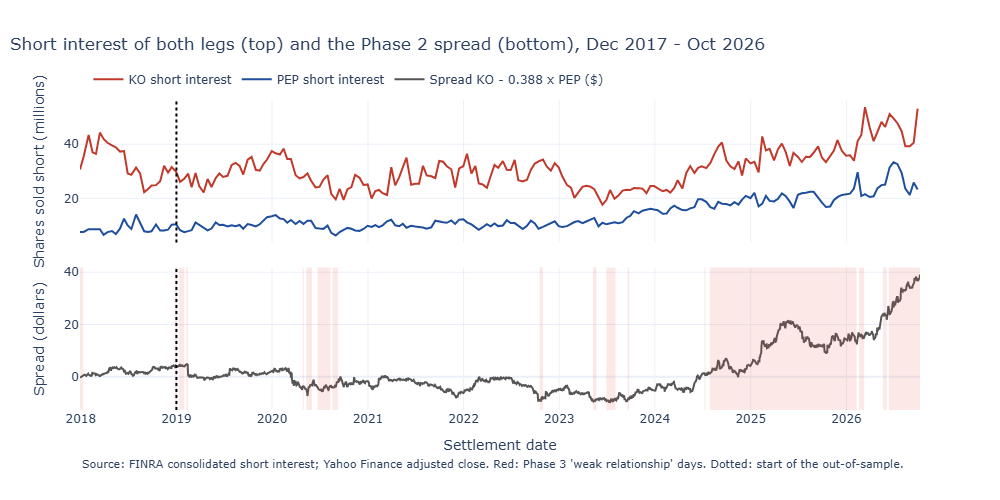

In [3]:
pv = rolling_adf_pvalue(spread, 500)  # Phase 3: 2-year rolling ADF on the frozen spread
weak = weak_labels(pv, pvalue_cutoff(pv, PAIR.in_sample_end, share=0.25))  # Phase 3 relative rule
first = si[A].index[0]
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08)
for t in (A, B):
    fig.add_trace(
        go.Scatter(
            x=si[t].index,
            y=si[t]["short_interest"] / 1e6,
            name=f"{t} short interest",
            line={"color": COLORS[t]},
        ),
        row=1,
        col=1,
    )
fig.add_trace(
    go.Scatter(
        x=spread.loc[first:].index,
        y=spread.loc[first:],
        name="Spread KO - 0.388 x PEP ($)",
        line={"color": "#555555"},
    ),
    row=2,
    col=1,
)
on = weak.loc[first:].fillna(0).astype(bool)
starts = on.index[on & ~on.shift(1, fill_value=False)]
ends = on.index[on & ~on.shift(-1, fill_value=False)]
for s0, s1 in zip(starts, ends, strict=True):
    fig.add_vrect(x0=s0, x1=s1, fillcolor="#e74c3c", opacity=0.12, line_width=0, row=2, col=1)
fig.add_vline(x=pd.Timestamp("2019-01-01"), line_dash="dot", line_color="black")
finish_figure(
    fig,
    "Short interest of both legs (top) and the Phase 2 spread (bottom), Dec 2017 - Oct 2026",
    "",
    "",
    SOURCE + " Red: Phase 3 'weak relationship' days. Dotted: start of the out-of-sample.",
)
fig.update_xaxes(title_text="Settlement date", row=2, col=1)
fig.update_yaxes(title_text="Shares sold short (millions)", row=1, col=1)
fig.update_yaxes(title_text="Spread (dollars)", row=2, col=1)
save_figure(fig, "04_short_interest", figures_dir)
fig.show()

**How to read it:** if short sellers reacted to the pair, the two lines on top would move apart when the
spread (bottom) moves, or around the red weak-relationship bands. **Reading.** Both lines climb from 2023 to
2026 while the spread climbs: in levels, more shorting of **both** stocks coincides with the break, not
more shorting of the loser. Short interest also jumps for a single date and falls back (KO in March 2026,
PEP in February 2026); section 2 tests whether these half-month changes line up with the spread.

## 2. The four comparisons, fixed before computing them

Written in my log (`ai/STATO.md`, 15:34 on the PC clock) before computing any of them, with the prediction
"nothing solid; if anything, comparison 1 (short sellers reacting to moves that already happened), not 2".

For each half-month between two settlement dates (210 intervals: 24 ending in 2018, 186 in 2019–2026):
**relative shorting** = change in log short interest of KO − change in log short interest of PEP
(positive: short sellers added more on KO than on PEP; logs make the two legs comparable).

| # | Question of the brief | Compared with relative shorting | Test |
|---|---|---|---|
| 1 | A divergence in the spread | Spread change over the same half-month | Rank correlation |
| 2 | ...that could be traded | Spread change over the 10 trading days **after publication** (settlement + 8 trading days, FINRA's usual delay) | Rank correlation |
| 3 | A period the relationship weakens | Size of relative shorting, intervals ending on a Phase 3 "weak" day vs the others | Welch t |
| 4 | A bigger-than-usual move | Size of relative shorting, the 10% largest spread moves vs the others | Welch t |

A **rank correlation** (Spearman) uses ranks instead of values, so one extreme date cannot drive it. As in
the other phases, |t| below about 2 can be luck; with four comparisons per period one near 2 is expected
by chance. 2018 (in-sample) and 2019–2026 (out-of-sample) are reported separately.

In [4]:
iv = interval_table(
    si[A]["short_interest"], si[B]["short_interest"], spread, publication_lag=8, horizon=10
)
iv["weak"] = weak.reindex(weak.index.union(iv.index)).ffill().reindex(iv.index)
big_move = float(iv["spread_change"].abs().quantile(0.9))
iv["big"] = (iv["spread_change"].abs() >= big_move).astype(float)
PERIODS = {"in-sample": ("2018-01-01", "2018-12-31"), "out-of-sample": ("2019-01-01", "2026-12-31")}
results, rows = {}, {}
for sample, (p0, p1) in PERIODS.items():
    d = iv.loc[p0:p1]
    tests = {
        "1 same half-month": spearman(d["rel_shorting"], d["spread_change"]),
        "2 after publication": spearman(d["rel_shorting"], d["next_spread_change"]),
    }
    for name, flag in (("3 weak periods", "weak"), ("4 big moves", "big")):
        g = compare_groups(d["rel_shorting"].abs(), d[flag])
        tests[name] = g if min(g["n_weak"], g["n_normal"]) >= 2 else None  # not computable
    for name, res in tests.items():
        results[(name, sample)] = res
        if res is None:
            rows[(name, sample)] = ["not computable", "", ""]
        elif "r" in res:
            rows[(name, sample)] = [
                f"{res['n']:.0f}",
                f"r = {res['r']:+.2f}",
                f"{res['t_stat']:+.2f}",
            ]
        else:
            rows[(name, sample)] = [
                f"{res['n_weak']:.0f} / {res['n_normal']:.0f}",
                f"{res['mean_weak']:.3f} vs {res['mean_normal']:.3f}",
                f"{res['welch_t']:+.2f}",
            ]
table = pd.DataFrame(rows, index=["intervals (flagged / other)", "effect", "t"]).T
table

,,intervals (flagged / other),effect,t
1 same half-month,in-sample,24,r = -0.04,-0.20
2 after publication,in-sample,24,r = +0.06,+0.27
3 weak periods,in-sample,not computable,,
4 big moves,in-sample,not computable,,
1 same half-month,out-of-sample,186,r = +0.00,+0.03
2 after publication,out-of-sample,185,r = +0.02,+0.20
3 weak periods,out-of-sample,61 / 125,0.114 vs 0.109,+0.35
4 big moves,out-of-sample,21 / 165,0.099 vs 0.113,-0.79


**Reading: nothing lines up, as predicted.**
- **1–2.** Out-of-sample the rank correlations are 0.00 and +0.02 (t = 0.03 and 0.20): knowing whether
  short sellers moved toward KO or toward PEP says nothing about the spread, neither in the same half-month
  nor after the number is public. 2018 says the same with 24 points.
- **3.** Out-of-sample, the typical half-month shift in relative shorting is 0.114 (about 11%) in the weak
  periods and 0.109 in the others (t = 0.35): no extra repositioning when the relationship weakens.
- **4.** On the 21 half-months with the largest spread moves (above 2.72 dollars) short sellers shift *less*
  than usual, 0.099 against 0.113 (t = −0.79), not more.
- In 2018 comparisons 3 and 4 cannot be computed: only 1 of its 24 intervals ends on a weak day and none
  is among the largest moves. I report this instead of replacing them with something else.

## 3. What I learn, and what I am unsure about

**Answer to the brief: no change in short interest lines up with the spread, its weak periods or its
large moves**, in 2018 or in 2019–2026. The one thing that coincides with the 2024–2026 break is a rise
of short interest on **both** stocks, which is a statement about the two companies, not about the pair.
Why I believe the null (my reading, not tested): short interest on these two very large, liquid stocks is
small (about 2–3 days of volume) and much of it is probably held for reasons other than a view on KO
against PEP (hedges of index and option positions), so a pairs view, if any, is drowned out.

**What I am unsure about.**
- Half-monthly data: a reaction that lasts days would be invisible.
- Only 2018 is in-sample; everything else is after the out-of-sample run, so this is description, not a
  validated signal.
- Publication delay: I used 8 trading days, FINRA's usual schedule, not the exact date of each release.
- I did not look for the reason behind each one-date spike.

## 4. How many things I tried

Six comparisons were computable among the eight fixed in advance (2 in 2018, 4 in 2019–2026). While
checking the data I also computed five things **not** fixed in advance (appendix). All eleven go in the
trial log.

In [5]:
explore = {}
for sample, (p0, p1) in PERIODS.items():
    d = iv.loc[p0:p1]
    for t, col in ((A, "d_log_si_a"), (B, "d_log_si_b")):
        key = (f"{t} short interest change vs spread change", sample)
        explore[key] = spearman(d[col], d["spread_change"])
level_ratio = np.log(si[A]["short_interest"] / si[B]["short_interest"])
explore[("log(KO/PEP short interest) level vs spread level", "2018-2026")] = spearman(
    level_ratio, spread.reindex(level_ratio.index, method="ffill")
)
PARAMS = {"source": "FINRA", "publication_lag": 8, "horizon": 10, "beta": S.beta}
for (name, sample), res in results.items():
    if res is None:
        continue
    p0, p1 = iv.loc[slice(*PERIODS[sample])].index[[0, -1]]
    log_trial(
        trials_db,
        "phase4-short-interest",
        PAIR_NAME,
        sample,
        (p0.date(), p1.date()),
        {**PARAMS, "comparison": name},
        res,
        "fixed in advance (ai/STATO.md, 15:34)",
    )
for (name, sample), res in explore.items():
    if (
        sample == "2018-2026"
    ):  # spans 2018 too; logged with the out-of-sample, where most of it lies
        p0, p1, sample = level_ratio.index[0], level_ratio.index[-1], "out-of-sample"
    else:
        p0, p1 = iv.loc[slice(*PERIODS[sample])].index[[0, -1]]
    log_trial(
        trials_db,
        "phase4-exploratory",
        PAIR_NAME,
        sample,
        (p0.date(), p1.date()),
        {**PARAMS, "comparison": name},
        res,
        "not fixed in advance",
    )
pd.Series(
    {
        "phase 4, fixed in advance": count_trials(trials_db, "phase4-short-interest"),
        "phase 4, exploratory": count_trials(trials_db, "phase4-exploratory"),
        "total in the log (all phases)": count_trials(trials_db),
    }
).to_frame("logged")

,logged
"phase 4, fixed in advance",6
"phase 4, exploratory",5
total in the log (all phases),73


## Appendix: the exploratory checks (not fixed in advance)

Per leg: does a stock's own short interest move with the spread? (The spread rises when KO beats PEP.)
And in levels: does the KO/PEP short-interest ratio track the spread over the whole period?

In [6]:
pd.DataFrame(
    {
        k: {"n": f"{v['n']:.0f}", "r": f"{v['r']:+.2f}", "t": f"{v['t_stat']:+.2f}"}
        for k, v in explore.items()
    }
).T

,,n,r,t
KO short interest change vs spread change,in-sample,24,+0.39,+1.99
PEP short interest change vs spread change,in-sample,24,+0.27,+1.29
KO short interest change vs spread change,out-of-sample,186,+0.07,+0.95
PEP short interest change vs spread change,out-of-sample,186,+0.05,+0.73
log(KO/PEP short interest) level vs spread level,2018-2026,211,-0.12,-1.80


**Reading.** Only one value comes near 2: in 2018 KO's short interest rose in the half-months in which KO
beat PEP (r = +0.39, t = 1.99 on 24 points), i.e. short sellers leaning against the winner. Out-of-sample
the same check gives t = 0.95. Among eleven checks one near 2 is what luck produces, so I read it as
noise. The level comparison (t = −1.80) is not meaningful: both series trend for years, and two trending
series correlate by accident.

In [7]:
# Every number quoted in the text, checked (expected values recorded on 10 Oct 2026)
assert len(nasdaq_pep) == 24 and "Nasdaq Listed" in ko_refusal and max_gap == 0
assert len(si[A]) == len(si[B]) == 211
assert si[A].index[0] == pd.Timestamp("2017-12-29")
assert si[A].index[-1] == pd.Timestamp("2026-09-30")
assert len(iv) == 210 and len(iv.loc["2018"]) == 24 and len(iv.loc["2019":]) == 186
y = yearly.round(2)
KO_SI, PEP_SI = "KO short interest (M shares)", "PEP short interest (M shares)"
assert y.loc[2023, KO_SI] == 22.84 and y.loc[2026, KO_SI] == 44.46
assert y.loc[2023, PEP_SI] == 12.23 and y.loc[2026, PEP_SI] == 25.17
ratio = yearly["KO/PEP price ratio"].round(3)  # text: 0.35 and 0.56, as in Phase 2
assert ratio.loc[2023] == 0.345 and ratio.loc[2026] == 0.558
assert round(yearly.loc[2023, "spread ($)"]) == -7 and round(yearly.loc[2026, "spread ($)"]) == 24
o = {k[0]: v for k, v in results.items() if k[1] == "out-of-sample"}
c1, c2 = o["1 same half-month"], o["2 after publication"]
assert round(c1["r"], 2) == 0.00 and round(c1["t_stat"], 2) == 0.03
assert round(c2["r"], 2) == 0.02 and round(c2["t_stat"], 2) == 0.20
g = o["3 weak periods"]
assert (g["n_weak"], g["n_normal"]) == (61, 125) and round(g["welch_t"], 2) == 0.35
assert round(g["mean_weak"], 3) == 0.114 and round(g["mean_normal"], 3) == 0.109
g = o["4 big moves"]
assert (g["n_weak"], g["n_normal"]) == (21, 165) and round(g["welch_t"], 2) == -0.79
assert round(g["mean_weak"], 3) == 0.099 and round(g["mean_normal"], 3) == 0.113
assert round(big_move, 2) == 2.72
assert results[("3 weak periods", "in-sample")] is None
assert results[("4 big moves", "in-sample")] is None
assert int(iv.loc["2018", "weak"].sum()) == 1 and int(iv.loc["2018", "big"].sum()) == 0
assert max(abs(r["t_stat"] if "t_stat" in r else r["welch_t"]) for r in results.values() if r) < 0.8
e = {k: (round(v["r"], 2), round(v["t_stat"], 2)) for k, v in explore.items()}
assert e[("KO short interest change vs spread change", "in-sample")] == (0.39, 1.99)
assert e[("KO short interest change vs spread change", "out-of-sample")][1] == 0.95
assert e[("log(KO/PEP short interest) level vs spread level", "2018-2026")][1] == -1.80
assert count_trials(trials_db, "phase4-short-interest") == 6
assert count_trials(trials_db, "phase4-exploratory") == 5
assert (figures_dir / "04_short_interest.png").exists()